# Healthcare Patient Survey BI Mini Project -- Reports

Runs the 8 sample reports from the BI Mini Project brief against the star schema in
`healthcare_bi.db` (`Dim_Country_Details`, `Dim_Hospital_Details`, `Dim_Measure_Details`,
`Dim_Survey_Details`, `Fact_Patient_Survey`), using only pandas + matplotlib.

> Note: `Dim_Country_Details` is populated at **county** grain (`Country_Name` holds the
> county name) rather than literal country, since the source data
> (`Health Care_Patient_survey_source.csv`) is US county-level and report requirements
> #3 and #5 explicitly ask about counties.


In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

conn = sqlite3.connect('healthcare_bi.db')

county   = pd.read_sql('select * from Dim_Country_Details', conn)
hospital = pd.read_sql('select * from Dim_Hospital_Details', conn)
measure  = pd.read_sql('select * from Dim_Measure_Details', conn)
survey   = pd.read_sql('select * from Dim_Survey_Details', conn)
fact     = pd.read_sql('select * from Fact_Patient_Survey', conn)

print(f"Dim_Country_Details:  {county.shape}")
print(f"Dim_Hospital_Details: {hospital.shape}")
print(f"Dim_Measure_Details:  {measure.shape}")
print(f"Dim_Survey_Details:   {survey.shape}")
print(f"Fact_Patient_Survey:  {fact.shape}")


Dim_Country_Details:  (629, 5)
Dim_Hospital_Details: (700, 5)
Dim_Measure_Details:  (50, 4)
Dim_Survey_Details:   (50, 4)
Fact_Patient_Survey:  (34999, 14)


## Build a hospital-level base table

Joins hospital + county, and pulls out the two metrics (completed surveys, response rate) that are constant per hospital for the survey period, plus the hospital's overall star rating.

In [2]:
h = hospital.drop(columns=['City']).merge(county, on='Country_Id').rename(columns={'Country_Name': 'County_Name'})

# Number of Completed Surveys & Survey Response Rate Percent are repeated identically
# across all 50 measure rows for a given hospital (they describe the survey period as
# a whole, not an individual question) -- so we take one value per hospital.
base = (
    fact.groupby('Hospital_Id')
        .agg(No_Completed_Surveys=('No_Completed_Surveys', 'max'),
             Survey_Response_Rate_Percent=('Survey_Response_Rate_Percent', 'max'))
        .reset_index()
        .merge(h, on='Hospital_Id')
)

overall_survey_id = survey.loc[survey.Survey_Question == 'Summary star rating', 'Survey_Id'].iloc[0]
overall_star = fact.loc[fact.Survey_Id == overall_survey_id, ['Hospital_Id', 'Patient_Survey_Star_Rating']]
base = base.merge(overall_star, on='Hospital_Id', how='left')

base.head()


,Hospital_Id,No_Completed_Surveys,Survey_Response_Rate_Percent,Hospital_Name,Country_Id,Location,County_Name,State,City,Zipcode,Patient_Survey_Star_Rating
0,10001,506.0,21.0,SOUTHEAST ALABAMA MEDICAL CENTER,1,"1108 ROSS CLARK CIRCLE DOTHAN, AL 36301 (31.214058, -85.361725)",HOUSTON,AL,DOTHAN,36301,2.0
1,10005,1135.0,34.0,MARSHALL MEDICAL CENTER SOUTH,2,"2505 U S HIGHWAY 431 NORTH BOAZ, AL 35957",MARSHALL,AL,BOAZ,35957,3.0
2,10006,579.0,22.0,ELIZA COFFEE MEMORIAL HOSPITAL,3,"205 MARENGO STREET FLORENCE, AL 35631 (34.79366, -87.684348)",LAUDERDALE,AL,FLORENCE,35631,2.0
3,10007,185.0,27.0,MIZELL MEMORIAL HOSPITAL,4,"702 N MAIN ST OPP, AL 36467 (31.291972, -86.255415)",COVINGTON,AL,OPP,36467,3.0
4,10008,63.0,31.0,CRENSHAW COMMUNITY HOSPITAL,5,"101 HOSPITAL CIRCLE LUVERNE, AL 36049 (31.692595, -86.266156)",CRENSHAW,AL,LUVERNE,36049,NaN


## Report 1: Number of Surveys Completed by Different Hospitals

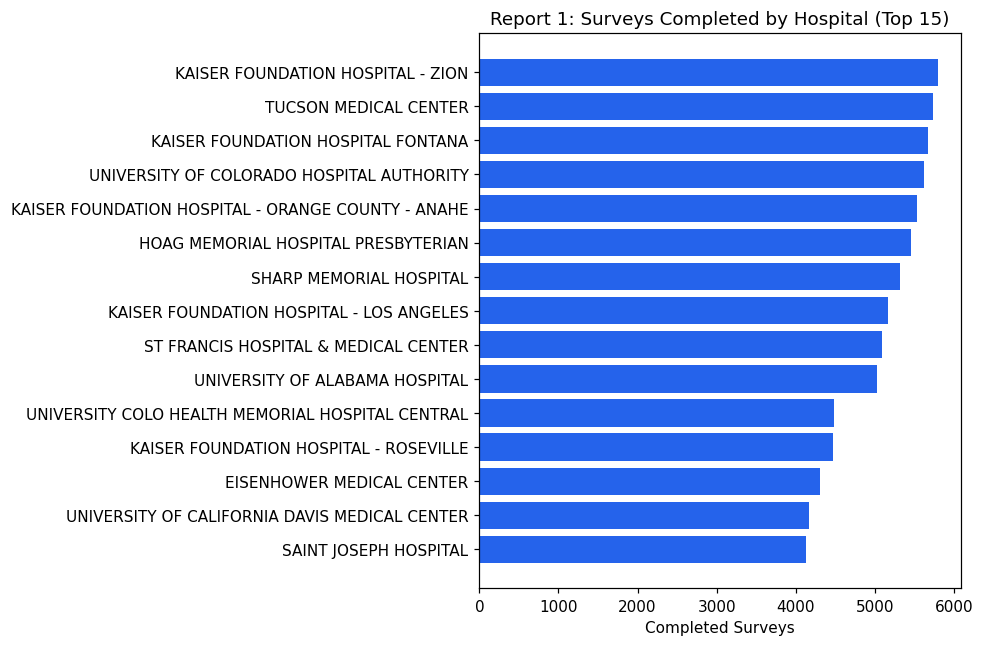

,Hospital_Name,City,State,No_Completed_Surveys
461,KAISER FOUNDATION HOSPITAL - ZION,SAN DIEGO,CA,5792.0
113,TUCSON MEDICAL CENTER,TUCSON,AZ,5739.0
342,KAISER FOUNDATION HOSPITAL FONTANA,FONTANA,CA,5668.0
621,UNIVERSITY OF COLORADO HOSPITAL AUTHORITY,AURORA,CO,5623.0
493,KAISER FOUNDATION HOSPITAL - ORANGE COUNTY - ANAHE,ANAHEIM,CA,5526.0
366,HOAG MEMORIAL HOSPITAL PRESBYTERIAN,NEWPORT BEACH,CA,5462.0
313,SHARP MEMORIAL HOSPITAL,SAN DIEGO,CA,5321.0
340,KAISER FOUNDATION HOSPITAL - LOS ANGELES,LOS ANGELES,CA,5170.0
688,ST FRANCIS HOSPITAL & MEDICAL CENTER,HARTFORD,CT,5084.0
16,UNIVERSITY OF ALABAMA HOSPITAL,BIRMINGHAM,AL,5024.0


In [3]:
report1 = (
    base[['Hospital_Name', 'City', 'State', 'No_Completed_Surveys']]
    .sort_values('No_Completed_Surveys', ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(report1['Hospital_Name'][::-1], report1['No_Completed_Surveys'][::-1], color='#2563eb')
ax.set_xlabel('Completed Surveys')
ax.set_title('Report 1: Surveys Completed by Hospital (Top 15)')
plt.tight_layout()
plt.show()

report1


## Report 2: Survey Response Rate by Measure ID, per Hospital

Using the 10 `*_LINEAR_SCORE` measures as the measure-category axis. Response rate is one number per hospital for the whole survey, so each hospital's line is flat across categories -- the chart compares hospitals' overall engagement levels rather than per-question variation.

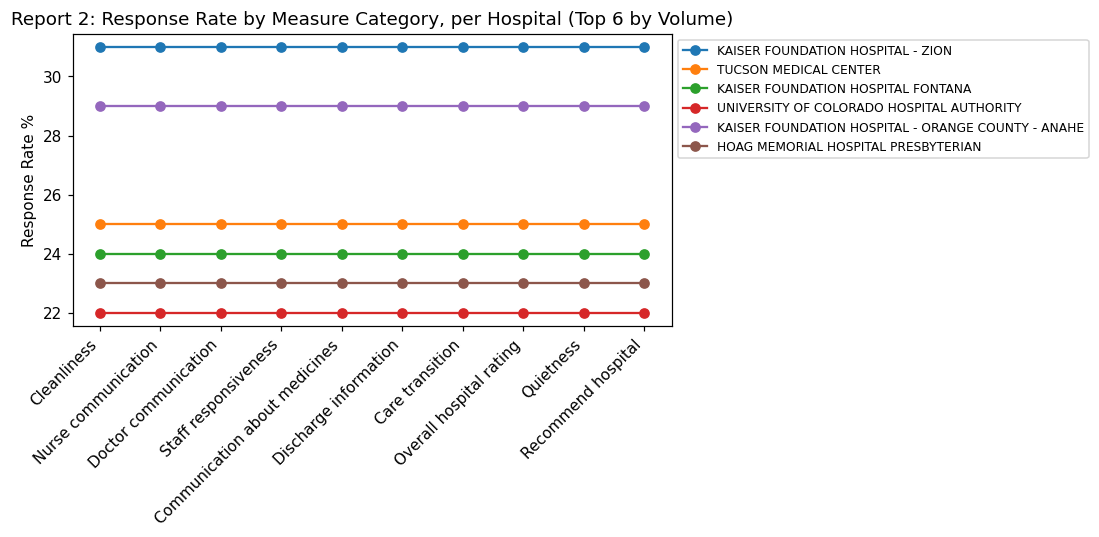

In [4]:
lin = survey[survey.Survey_Question.str.contains('linear mean score')][['Survey_Id', 'Survey_Question']].copy()
lin['Category'] = lin['Survey_Question'].str.replace(' - linear mean score', '', regex=False)

r2 = (
    fact[fact.Survey_Id.isin(lin.Survey_Id)][['Hospital_Id', 'Survey_Id', 'Answer_Percent', 'Linear_Mean_Value']]
    .merge(lin, on='Survey_Id')
    .merge(base[['Hospital_Id', 'Hospital_Name', 'Survey_Response_Rate_Percent']], on='Hospital_Id')
)

top6_ids = base.sort_values('No_Completed_Surveys', ascending=False).head(6)['Hospital_Id']

fig, ax = plt.subplots(figsize=(10, 5))
for hid in top6_ids:
    sub = r2[r2.Hospital_Id == hid].set_index('Category').reindex(lin['Category'])
    ax.plot(sub.index, sub['Survey_Response_Rate_Percent'], marker='o', label=sub['Hospital_Name'].iloc[0])
ax.set_ylabel('Response Rate %')
ax.set_title('Report 2: Response Rate by Measure Category, per Hospital (Top 6 by Volume)')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## Report 3: Top 3 Counties by Survey Response Rate

In [5]:
report3 = (
    base.groupby(['County_Name', 'State'])['Survey_Response_Rate_Percent']
        .mean()
        .reset_index()
        .sort_values('Survey_Response_Rate_Percent', ascending=False)
        .head(3)
)
report3


,County_Name,State,Survey_Response_Rate_Percent
219,SUTTER,CA,44.0
116,LA PLATA,CO,43.5
189,RUSSELL,AL,43.0


## Report 4: Top 10 Hospitals Based on Survey Response Rate

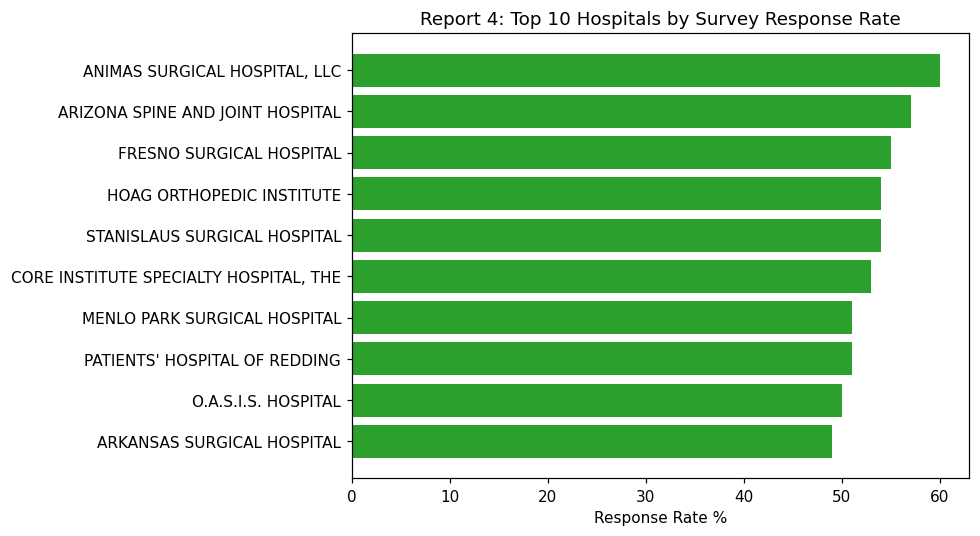

,Hospital_Name,City,State,Survey_Response_Rate_Percent
645,"ANIMAS SURGICAL HOSPITAL, LLC",DURANGO,CO,60.0
153,ARIZONA SPINE AND JOINT HOSPITAL,MESA,AZ,57.0
514,FRESNO SURGICAL HOSPITAL,FRESNO,CA,55.0
547,HOAG ORTHOPEDIC INSTITUTE,IRVINE,CA,54.0
521,STANISLAUS SURGICAL HOSPITAL,MODESTO,CA,54.0
154,"CORE INSTITUTE SPECIALTY HOSPITAL, THE",PHOENIX,AZ,53.0
536,MENLO PARK SURGICAL HOSPITAL,MENLO PARK,CA,51.0
511,PATIENTS' HOSPITAL OF REDDING,REDDING,CA,51.0
167,O.A.S.I.S. HOSPITAL,PHOENIX,AZ,50.0
230,ARKANSAS SURGICAL HOSPITAL,NO LITTLE ROCK,AR,49.0


In [6]:
report4 = (
    base[['Hospital_Name', 'City', 'State', 'Survey_Response_Rate_Percent']]
    .sort_values('Survey_Response_Rate_Percent', ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(report4['Hospital_Name'][::-1], report4['Survey_Response_Rate_Percent'][::-1], color='#2ca02c')
ax.set_xlabel('Response Rate %')
ax.set_title('Report 4: Top 10 Hospitals by Survey Response Rate')
plt.tight_layout()
plt.show()

report4


## Report 5: County and City-wise Hospital Rating (Drill-down)

In [7]:
report5 = (
    base.dropna(subset=['Patient_Survey_Star_Rating'])
        .groupby(['State', 'County_Name', 'City'])['Patient_Survey_Star_Rating']
        .mean()
        .round(2)
        .reset_index()
        .sort_values(['State', 'County_Name', 'City'])
)

print(f"{len(report5)} State/County/City combinations have a rating")
report5.sort_values('Patient_Survey_Star_Rating', ascending=False).head(15)


388 State/County/City combinations have a rating


,State,County_Name,City,Patient_Survey_Star_Rating
323,CA,SUTTER,YUBA CITY,5.0
16,AL,CHILTON,CLANTON,5.0
296,CA,SAN MATEO,MENLO PARK,5.0
237,CA,ORANGE,IRVINE,5.0
231,CA,NEVADA,TRUCKEE,5.0
92,AR,PULASKI,NO LITTLE ROCK,5.0
225,CA,MONO,MAMMOTH LAKES,5.0
81,AR,HOT SPRING,MALVERN,5.0
349,CO,CHAFFEE,SALIDA,5.0
63,AR,ARKANSAS,STUTTGART,5.0


## Report 6: Hospitals Which Are in the Same City

In [8]:
city_counts = base.groupby(['City', 'State'])['Hospital_Id'].count().reset_index(name='Num_Hospitals')
report6 = city_counts[city_counts.Num_Hospitals > 1].sort_values('Num_Hospitals', ascending=False)

print(f"{len(report6)} cities have more than one hospital in the dataset")
report6.head(15)


86 cities have more than one hospital in the dataset


,City,State,Num_Hospitals
255,LOS ANGELES,CA,19
345,PHOENIX,AZ,14
390,SAN FRANCISCO,CA,10
38,BIRMINGHAM,AL,8
380,SACRAMENTO,CA,7
112,DENVER,CO,6
461,TUCSON,AZ,6
24,BAKERSFIELD,CA,6
388,SAN DIEGO,CA,6
276,MESA,AZ,6


In [9]:
top_city, top_state = report6.iloc[0][['City', 'State']]
print(f"Hospitals in {top_city}, {top_state}:")
base.loc[(base.City == top_city) & (base.State == top_state), 'Hospital_Name'].tolist()


Hospitals in LOS ANGELES, CA:


['HOLLYWOOD PRESBYTERIAN MEDICAL CENTER', 'WHITE MEMORIAL MEDICAL CENTER', 'KAISER FOUNDATION HOSPITAL - LOS ANGELES', 'CALIFORNIA HOSPITAL MEDICAL CENTER LA', 'RONALD REAGAN U C L A MEDICAL CENTER', 'LAC+USC MEDICAL CENTER', 'GOOD SAMARITAN HOSPITAL', 'SAINT VINCENT MEDICAL CENTER', 'KAISER FOUNDATION HOSPITAL - WEST LA', 'CEDARS-SINAI MEDICAL CENTER', 'EAST LOS ANGELES DOCTORS HOSPITAL', 'LOS ANGELES COMMUNITY HOSPITAL', 'KECK HOSPITAL OF USC', 'OLYMPIA MEDICAL CENTER', 'MIRACLE MILE MEDICAL CENTER', 'SILVER LAKE MEDICAL CENTER', 'MARTIN LUTHER KING, JR. COMMUNITY HOSPITAL', "CHILDREN'S HOSP OF LOS ANGELES", 'SHRINERS HOSPITALS FOR CHILDREN']

## Report 7: Total Survey Response Rate by All Hospitals

mean      23.77
median    23.00
min        7.00
max       60.00
Name: Survey_Response_Rate_Percent, dtype: float64


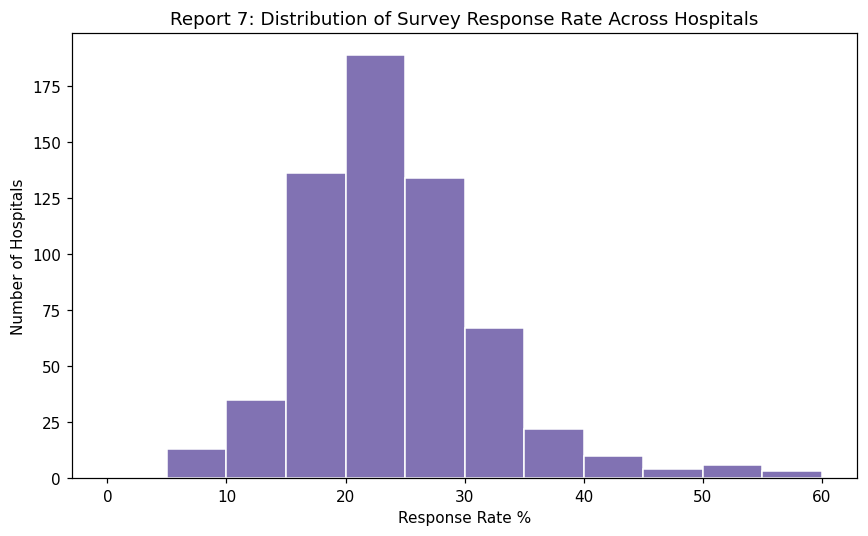

In [10]:
report7_summary = base['Survey_Response_Rate_Percent'].agg(['mean', 'median', 'min', 'max']).round(2)
print(report7_summary)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(base['Survey_Response_Rate_Percent'].dropna(), bins=range(0, 65, 5), color='#8172b3', edgecolor='white')
ax.set_xlabel('Response Rate %')
ax.set_ylabel('Number of Hospitals')
ax.set_title('Report 7: Distribution of Survey Response Rate Across Hospitals')
plt.tight_layout()
plt.show()


## Report 8: New Insight -- What Drives Patient Satisfaction?

Lowest-scoring category nationally:  Communication about medicines (avg 78.6)
Highest-scoring category nationally: Doctor communication (avg 90.5)
Correlation between response rate and overall star rating: r = 0.559

Insight: hospitals that get more patients to complete the survey tend to be rated
higher overall, and 'Communication about medicines' is consistently the weakest
HCAHPS category nationally -- a clear improvement target across hospitals.


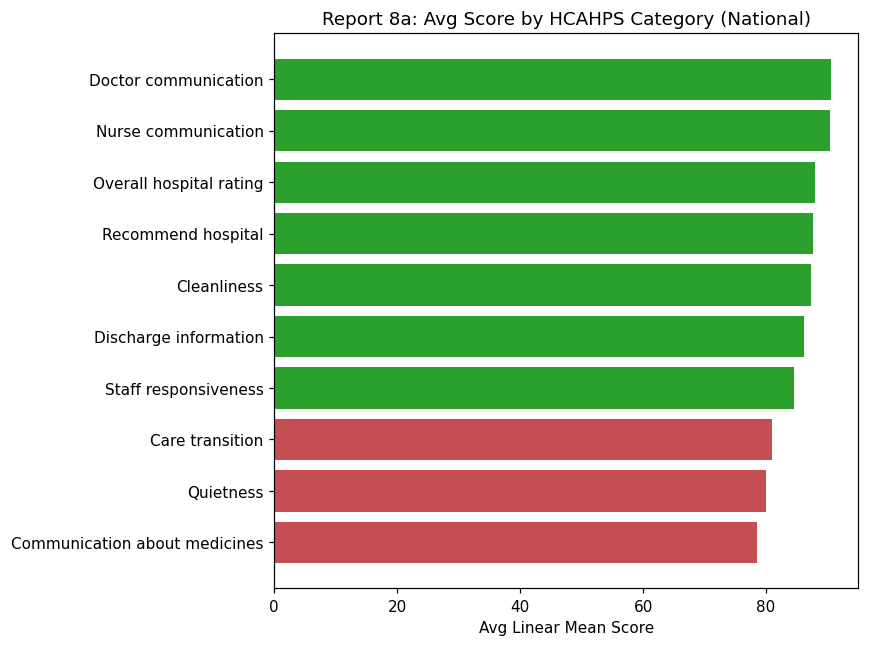

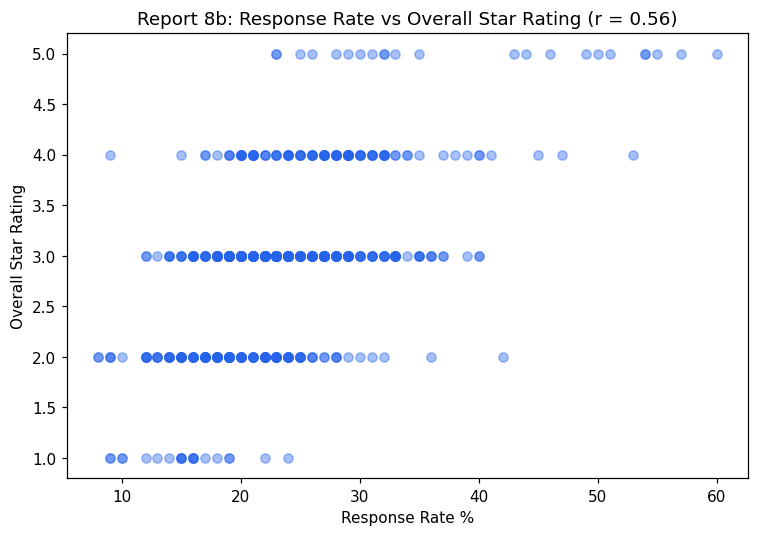

In [11]:
cat_avg = r2.groupby('Category')['Linear_Mean_Value'].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#c44e52' if v < 83 else '#2ca02c' for v in cat_avg.values]
ax.barh(cat_avg.index, cat_avg.values, color=colors)
ax.set_xlabel('Avg Linear Mean Score')
ax.set_title('Report 8a: Avg Score by HCAHPS Category (National)')
plt.tight_layout()
plt.show()

corr_df = base.dropna(subset=['Survey_Response_Rate_Percent', 'Patient_Survey_Star_Rating'])
corr = corr_df['Survey_Response_Rate_Percent'].corr(corr_df['Patient_Survey_Star_Rating'])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(corr_df['Survey_Response_Rate_Percent'], corr_df['Patient_Survey_Star_Rating'], alpha=0.4, color='#2563eb')
ax.set_xlabel('Response Rate %')
ax.set_ylabel('Overall Star Rating')
ax.set_title(f'Report 8b: Response Rate vs Overall Star Rating (r = {corr:.2f})')
plt.tight_layout()
plt.show()

print(f"Lowest-scoring category nationally:  {cat_avg.index[0]} (avg {cat_avg.iloc[0]:.1f})")
print(f"Highest-scoring category nationally: {cat_avg.index[-1]} (avg {cat_avg.iloc[-1]:.1f})")
print(f"Correlation between response rate and overall star rating: r = {corr:.3f}")
print()
print("Insight: hospitals that get more patients to complete the survey tend to be rated")
print("higher overall, and 'Communication about medicines' is consistently the weakest")
print("HCAHPS category nationally -- a clear improvement target across hospitals.")
